In [ ]:
#exp-7 => texture analysis using GLCM

In [2]:
import sys
print(sys.executable)

c:\Users\monis\AppData\Local\Programs\Python\Python313\python.exe


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.feature import graycomatrix, graycoprops
from mpl_toolkits.mplot3d import Axes3D
from matplotlib.patches import Rectangle

In [2]:
image = data.camera()

print("Image shape:", image.shape)
print("Image data type:", image.dtype)

Image shape: (512, 512)
Image data type: uint8


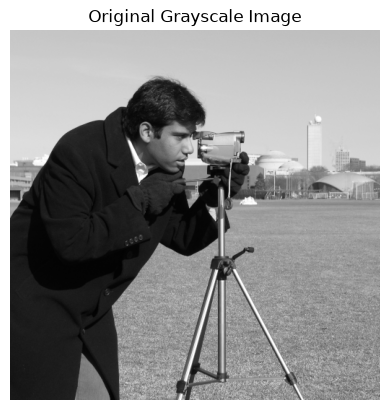

In [3]:
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

In [4]:
PATCH_SIZE = 21

grass_locations = [
    (280, 454),
    (342, 223),
    (444, 192),
    (455, 455)
]

sky_locations = [
    (38, 34),
    (139, 28),
    (37, 437),
    (145, 379)
]

grass_patches = []
sky_patches = []

for row, col in grass_locations:
    patch = image[row:row + PATCH_SIZE, col:col + PATCH_SIZE]
    grass_patches.append(patch)

for row, col in sky_locations:
    patch = image[row:row + PATCH_SIZE, col:col + PATCH_SIZE]
    sky_patches.append(patch)

print("Number of grass patches:", len(grass_patches))
print("Number of sky patches:", len(sky_patches))
print("Patch size:", grass_patches[0].shape)

Number of grass patches: 4
Number of sky patches: 4
Patch size: (21, 21)


In [5]:
distance = [5]
angle = [0]

grass_glcms = []
sky_glcms = []

for patch in grass_patches:
    glcm = graycomatrix(
        patch,
        distances=distance,
        angles=angle,
        levels=256,
        symmetric=True,
        normed=True
    )
    grass_glcms.append(glcm)

for patch in sky_patches:
    glcm = graycomatrix(
        patch,
        distances=distance,
        angles=angle,
        levels=256,
        symmetric=True,
        normed=True
    )
    sky_glcms.append(glcm)

print("Grass GLCMs:", len(grass_glcms))
print("Sky GLCMs:", len(sky_glcms))
print("GLCM shape:", grass_glcms[0].shape)

Grass GLCMs: 4
Sky GLCMs: 4
GLCM shape: (256, 256, 1, 1)


In [6]:
def extract_features(glcm):
    features = {}

    features["Dissimilarity"] = graycoprops(glcm, "dissimilarity")[0, 0]
    features["Correlation"] = graycoprops(glcm, "correlation")[0, 0]
    features["Contrast"] = graycoprops(glcm, "contrast")[0, 0]
    features["Homogeneity"] = graycoprops(glcm, "homogeneity")[0, 0]
    features["ASM"] = graycoprops(glcm, "ASM")[0, 0]
    features["Energy"] = graycoprops(glcm, "energy")[0, 0]

    return features

In [7]:
grass_features = []
sky_features = []

for glcm in grass_glcms:
    features = extract_features(glcm)
    grass_features.append(features)

for glcm in sky_glcms:
    features = extract_features(glcm)
    sky_features.append(features)

print("Grass features:")
for i, feature in enumerate(grass_features):
    print("Grass", i + 1, feature)

print("\nSky features:")
for i, feature in enumerate(sky_features):
    print("Sky", i + 1, feature)

Grass features:
Grass 1 {'Dissimilarity': np.float64(6.0446428571428585), 'Correlation': np.float64(0.18465981611100118), 'Contrast': np.float64(57.72916666666668), 'Homogeneity': np.float64(0.1560802170950511), 'ASM': np.float64(0.003857532596371883), 'Energy': np.float64(0.06210903796044408)}
Grass 2 {'Dissimilarity': np.float64(11.973214285714286), 'Correlation': np.float64(0.09819326975998051), 'Contrast': np.float64(217.41964285714286), 'Homogeneity': np.float64(0.06857186383263617), 'ASM': np.float64(0.0023162910997732425), 'Energy': np.float64(0.04812786199046497)}
Grass 3 {'Dissimilarity': np.float64(18.794642857142854), 'Correlation': np.float64(0.012329737526846556), 'Contrast': np.float64(564.7232142857142), 'Homogeneity': np.float64(0.051039687157081494), 'ASM': np.float64(0.001806972789115646), 'Energy': np.float64(0.04250850255085029)}
Grass 4 {'Dissimilarity': np.float64(18.80059523809524), 'Correlation': np.float64(0.03211156902114872), 'Contrast': np.float64(554.639880

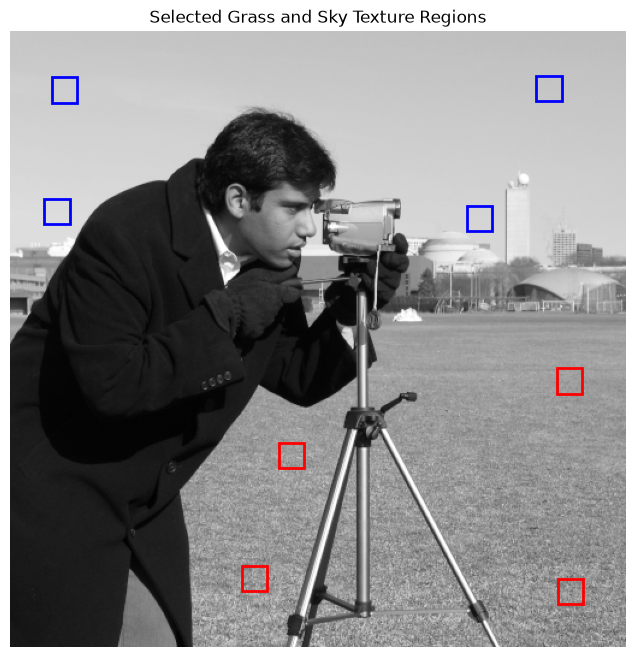

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")

for row, col in grass_locations:
    rectangle = Rectangle(
        (col, row),
        PATCH_SIZE,
        PATCH_SIZE,
        edgecolor="red",
        facecolor="none",
        linewidth=2
    )
    ax.add_patch(rectangle)

for row, col in sky_locations:
    rectangle = Rectangle(
        (col, row),
        PATCH_SIZE,
        PATCH_SIZE,
        edgecolor="blue",
        facecolor="none",
        linewidth=2
    )
    ax.add_patch(rectangle)

ax.set_title("Selected Grass and Sky Texture Regions")
ax.axis("off")

plt.show()

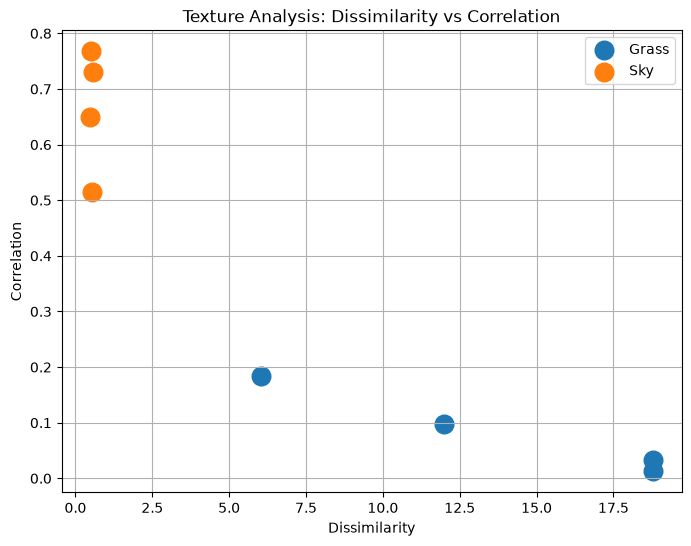

In [11]:
grass_dissimilarity = []
grass_correlation = []

sky_dissimilarity = []
sky_correlation = []

for feature in grass_features:
    grass_dissimilarity.append(feature["Dissimilarity"])
    grass_correlation.append(feature["Correlation"])

for feature in sky_features:
    sky_dissimilarity.append(feature["Dissimilarity"])
    sky_correlation.append(feature["Correlation"])

plt.figure(figsize=(8, 6))

plt.scatter(
    grass_dissimilarity,
    grass_correlation,
    label="Grass",
    s=180
)

plt.scatter(
    sky_dissimilarity,
    sky_correlation,
    label="Sky",
    s=180
)

plt.xlabel("Dissimilarity")
plt.ylabel("Correlation")
plt.title("Texture Analysis: Dissimilarity vs Correlation")
plt.legend()
plt.grid(True)

plt.show()

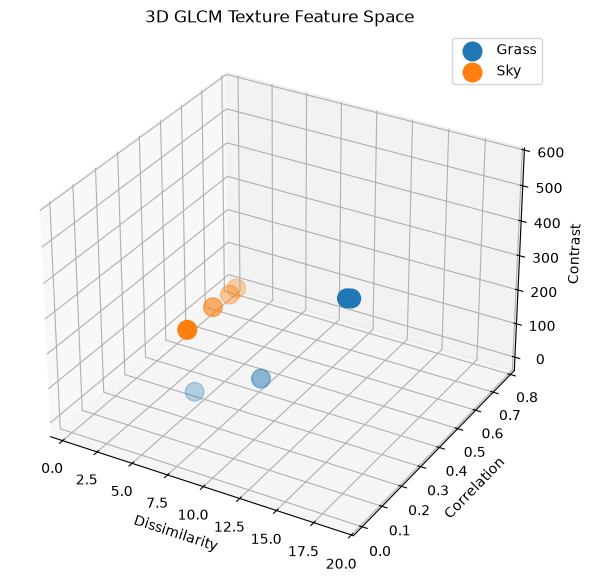

In [12]:
grass_contrast = []
sky_contrast = []

for feature in grass_features:
    grass_contrast.append(feature["Contrast"])

for feature in sky_features:
    sky_contrast.append(feature["Contrast"])

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    grass_dissimilarity,
    grass_correlation,
    grass_contrast,
    label="Grass",
    s=180
)

ax.scatter(
    sky_dissimilarity,
    sky_correlation,
    sky_contrast,
    label="Sky",
    s=180
)

ax.set_xlabel("Dissimilarity")
ax.set_ylabel("Correlation")
ax.set_zlabel("Contrast")

ax.set_title("3D GLCM Texture Feature Space")
ax.legend()

plt.show()

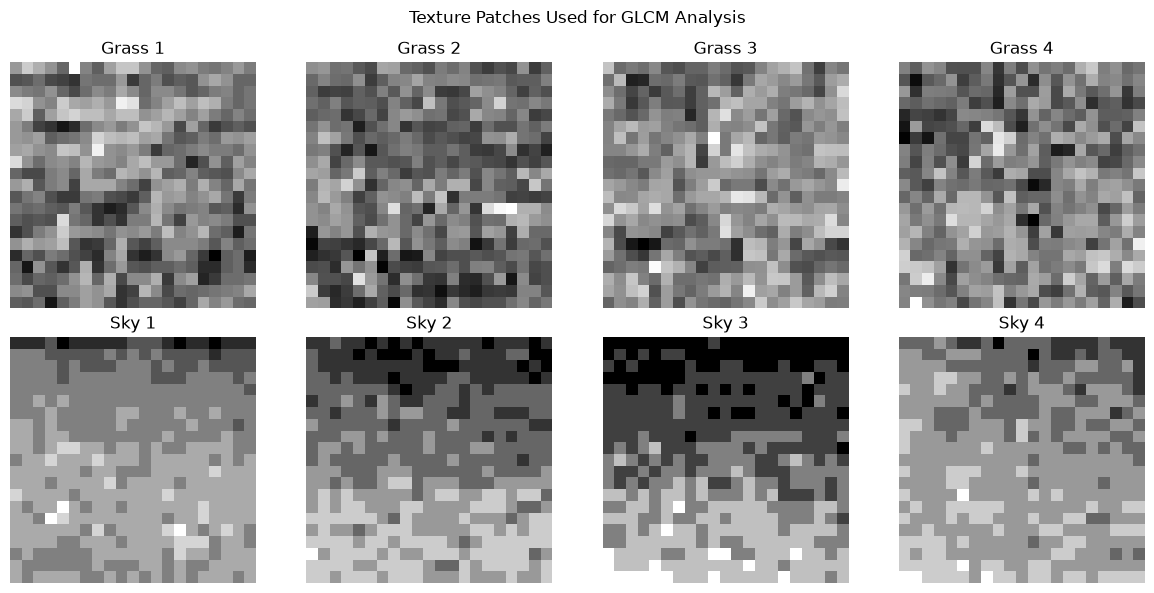

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i in range(4):
    axes[0, i].imshow(grass_patches[i], cmap="gray")
    axes[0, i].set_title("Grass " + str(i + 1))
    axes[0, i].axis("off")

for i in range(4):
    axes[1, i].imshow(sky_patches[i], cmap="gray")
    axes[1, i].set_title("Sky " + str(i + 1))
    axes[1, i].axis("off")

plt.suptitle("Texture Patches Used for GLCM Analysis")
plt.tight_layout()
plt.show()

In [14]:
print("GLCM Texture Features")
print("-" * 100)

for i, feature in enumerate(grass_features):
    print("Grass", i + 1)
    for name, value in feature.items():
        print(f"  {name}: {value:.4f}")
    print()

for i, feature in enumerate(sky_features):
    print("Sky", i + 1)
    for name, value in feature.items():
        print(f"  {name}: {value:.4f}")
    print()

GLCM Texture Features
----------------------------------------------------------------------------------------------------
Grass 1
  Dissimilarity: 6.0446
  Correlation: 0.1847
  Contrast: 57.7292
  Homogeneity: 0.1561
  ASM: 0.0039
  Energy: 0.0621

Grass 2
  Dissimilarity: 11.9732
  Correlation: 0.0982
  Contrast: 217.4196
  Homogeneity: 0.0686
  ASM: 0.0023
  Energy: 0.0481

Grass 3
  Dissimilarity: 18.7946
  Correlation: 0.0123
  Contrast: 564.7232
  Homogeneity: 0.0510
  ASM: 0.0018
  Energy: 0.0425

Grass 4
  Dissimilarity: 18.8006
  Correlation: 0.0321
  Contrast: 554.6399
  Homogeneity: 0.0442
  ASM: 0.0018
  Energy: 0.0426

Sky 1
  Dissimilarity: 0.4673
  Correlation: 0.6500
  Contrast: 0.5446
  Homogeneity: 0.7741
  ASM: 0.1660
  Energy: 0.4075

Sky 2
  Dissimilarity: 0.5744
  Correlation: 0.7304
  Contrast: 0.6935
  Homogeneity: 0.7247
  ASM: 0.0941
  Energy: 0.3068

Sky 3
  Dissimilarity: 0.5208
  Correlation: 0.7674
  Contrast: 0.5863
  Homogeneity: 0.7461
  ASM: 0.1023
  